# Task1


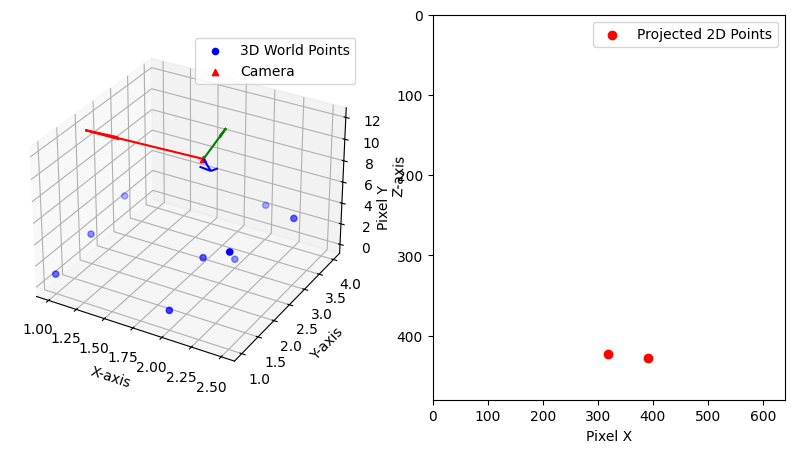

Ground Truth Projection Matrix (P):
 [[-813.39199048  -61.43422386 -277.52352325 5440.        ]
 [ -74.21369291  704.14933053 -215.0954395  4280.        ]
 [  -0.05517433    0.03015767   -0.9980212    12.        ]]


In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Function to create a rotation matrix from yaw, pitch, and roll angles
def create_rotation_matrix(yaw, pitch, roll):
    yaw = np.radians(yaw)
    pitch = np.radians(pitch)
    roll = np.radians(roll)

    R_yaw = np.array([[np.cos(yaw), 0, np.sin(yaw)],
                      [0, 1, 0],
                      [-np.sin(yaw), 0, np.cos(yaw)]])

    R_pitch = np.array([[1, 0, 0],
                        [0, np.cos(pitch), -np.sin(pitch)],
                        [0, np.sin(pitch), np.cos(pitch)]])

    R_roll = np.array([[np.cos(roll), -np.sin(roll), 0],
                       [np.sin(roll), np.cos(roll), 0],
                       [0, 0, 1]])

    return R_roll @ R_pitch @ R_yaw

# Function to create camera parameters
def createGTCameraParameters(fx, fy, cx, cy, R, t):
    K = np.array([[fx, 0, cx],
                  [0, fy, cy],
                  [0,  0,  1]])

    RT = np.hstack((R, t.reshape(-1, 1)))
    P = K @ RT

    return P, RT, K

# Function to project 3D world points into 2D pixel coordinates
def project_world_to_camera(points_3d, P):
    homogeneous_points = np.hstack((points_3d, np.ones((points_3d.shape[0], 1))))
    projected_points = P @ homogeneous_points.T
    projected_points /= projected_points[2, :]  # Normalize by the depth

    return projected_points[:2, :].T

# Function to plot 3D world points and the camera
def plotWorldPoints(ax, points, R, camera_origin):
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], c='b', marker='o', label='3D World Points')
    ax.scatter(camera_origin[0], camera_origin[1], camera_origin[2], c='r', marker='^', label='Camera')

    # Draw camera axes
    camera_axes = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]])
    transformed_axes = R.T @ camera_axes.T

    colors = ['r', 'g', 'b']
    for i in range(3):
        ax.quiver(camera_origin[0], camera_origin[1], camera_origin[2],
                  transformed_axes[0, i], transformed_axes[1, i], transformed_axes[2, i], color=colors[i])

    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')
    ax.set_zlabel('Z-axis')
    ax.legend()

# Function to plot projected 2D points
def plotImagePixelPoints(ax, image_points, image_width, image_height):
    ax.scatter(image_points[:, 0], image_points[:, 1], c='r', marker='o', label='Projected 2D Points')
    ax.set_xlim([0, image_width])
    ax.set_ylim([image_height, 0])
    ax.set_xlabel('Pixel X')
    ax.set_ylabel('Pixel Y')
    ax.legend()

# Define camera parameters (given in the task)
focal_length_x = 800.0
focal_length_y = 700.0
principal_point_x = 320.0
principal_point_y = 240.0
image_width = 640
image_height = 480

# Define updated camera rotations
camera_yaw = 3
camera_pitch = 2
camera_roll = 5
camera_translation_vector = np.array([2, 2, 12])

# Compute Rotation Matrix
camera_rotation_matrix = create_rotation_matrix(camera_yaw, camera_pitch, camera_roll)
camera_rotation_matrix[:, 0] = -camera_rotation_matrix[:, 0]  # Flip X-axis
camera_rotation_matrix[:, 2] = -camera_rotation_matrix[:, 2]  # Flip Z-axis
R = camera_rotation_matrix.T

# Compute Projection Matrix
P, RT, K = createGTCameraParameters(focal_length_x, focal_length_y, principal_point_x, principal_point_y, R, camera_translation_vector)

# Define given non-coplanar 3D world points
world_3D_points = np.array([
    [1.0, 1.0, 1.0],
    [1.0, 2.0, 2.0],
    [1.0, 3.0, 3.0],
    [2.0, 1.0, 1.0],
    [2.0, 2.0, 3.0],
    [2.0, 3.0, 0.0],
    [2.0, 4.0, 2.5],
    [2.5, 1.0, 8.0],
    [2.5, 3.0, 5.5]
], dtype=np.float32)

# Project 3D points to 2D
camera_pixel_2D_points = project_world_to_camera(world_3D_points, P)

# Create Plots
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122)

plotWorldPoints(ax1, world_3D_points, camera_rotation_matrix, camera_translation_vector)
plotImagePixelPoints(ax2, camera_pixel_2D_points, image_width, image_height)

plt.show()

# Print Ground Truth Projection Matrix
print("Ground Truth Projection Matrix (P):\n", P)


# Task2

In [30]:
import numpy as np

def find_projection_matrix(world_3D_points, camera_pixel_2D_points):
    num_points = world_3D_points.shape[0]
    A = []

    for i in range(num_points):
        X, Y, Z = world_3D_points[i]
        u, v = camera_pixel_2D_points[i]

        A.append([X, Y, Z, 1, 0, 0, 0, 0, -u*X, -u*Y, -u*Z, -u])
        A.append([0, 0, 0, 0, X, Y, Z, 1, -v*X, -v*Y, -v*Z, -v])

    A = np.array(A)
    U, S, Vt = np.linalg.svd(A)
    P_estimated = Vt[-1].reshape(3, 4)

    # Scale the projection matrix
    P_estimated /= P_estimated[-1, -1]

    return P_estimated

# Compute the estimated projection matrix
P_estimated = find_projection_matrix(world_3D_points, camera_pixel_2D_points)

# Print Ground Truth and Estimated Projection Matrices
print("Ground Truth Projection Matrix (P):\n", P)
print("Estimated Projection Matrix (P_estimated):\n", P_estimated)

# Check for sign difference
sign_difference = np.sign(P) == np.sign(P_estimated)
if not np.all(sign_difference):
    P_estimated *= -1  # Adjust sign to match ground truth
    print("Adjusted Estimated Projection Matrix (P_estimated):\n", P_estimated)

Ground Truth Projection Matrix (P):
 [[-813.39199048  -61.43422386 -277.52352325 5440.        ]
 [ -74.21369291  704.14933053 -215.0954395  4280.        ]
 [  -0.05517433    0.03015767   -0.9980212    12.        ]]
Estimated Projection Matrix (P_estimated):
 [[-67.78266587  -5.11951866 -23.12696027 453.33333333]
 [ -6.18447441  58.67911088 -17.92461996 356.66666667]
 [ -0.00459786   0.00251314  -0.08316843   1.        ]]


In [32]:
# Check for sign difference
sign_difference = np.sign(P_ground_truth) == np.sign(P_estimated)

# Print the sign comparison
print("\nSign Difference Matrix:\n", sign_difference)

# If any sign difference exists, flip the estimated matrix
if not np.all(sign_difference):
    print("\nSign Difference Found! Flipping P_estimated...\n")
    P_estimated *= -1  # Adjust sign to match ground truth
    print("Adjusted Estimated Projection Matrix (P_estimated):\n", P_estimated)
else:
    print("\nNo sign difference detected. Matrices have the same sign structure.")



Sign Difference Matrix:
 [[ True  True  True  True]
 [ True  True  True  True]
 [False  True  True  True]]

Sign Difference Found! Flipping P_estimated...

Adjusted Estimated Projection Matrix (P_estimated):
 [[  67.78266587    5.11951866   23.12696027 -453.33333333]
 [   6.18447441  -58.67911088   17.92461996 -356.66666667]
 [   0.00459786   -0.00251314    0.08316843   -1.        ]]


The sign difference happens because the DLT algorithm finds the projection matrix up to a scale factor. Since multiplying a projection matrix by -1 does not change the 2D projections, the estimated matrix can have the opposite sign compared to the ground truth P.

To fix this, we simply check if most values have opposite signs and, if needed, multiply PestimateD  by -1. This makes it match the ground truth while keeping the projections correct.

# Task 3

In [33]:
import numpy as np

def find_projection_matrix(world_3D_points, camera_pixel_2D_points):
    num_points = world_3D_points.shape[0]
    A = []

    for i in range(num_points):
        X, Y, Z = world_3D_points[i]
        u, v = camera_pixel_2D_points[i]

        A.append([X, Y, Z, 1, 0, 0, 0, 0, -u*X, -u*Y, -u*Z, -u])
        A.append([0, 0, 0, 0, X, Y, Z, 1, -v*X, -v*Y, -v*Z, -v])

    A = np.array(A)
    U, S, Vt = np.linalg.svd(A)
    P_estimated = Vt[-1].reshape(3, 4)

    # Scale the projection matrix
    P_estimated /= P_estimated[-1, -1]

    return P_estimated

def decompose_projection_matrix(P):
    M = P[:, :3]
    t = P[:, 3]

    # Compute intrinsic (K) and rotation (R) using RQ decomposition
    from scipy.linalg import rq
    K, R = rq(M)

    # Normalize K
    K /= K[2, 2]

    # Compute camera center
    C = -np.linalg.inv(M) @ t

    fx, fy = K[0, 0], K[1, 1]
    cx, cy = K[0, 2], K[1, 2]

    return fx, fy, cx, cy, R, t, C

def project_points(P, world_3D_points):
    homogeneous_points = np.hstack((world_3D_points, np.ones((world_3D_points.shape[0], 1))))
    projected_points = P @ homogeneous_points.T
    projected_points /= projected_points[2, :]  # Normalize by depth
    return projected_points[:2, :].T

def compute_projection_error(ground_truth_2D, estimated_2D):
    errors = np.linalg.norm(ground_truth_2D - estimated_2D, axis=1)
    return np.mean(errors)

# Compute the estimated projection matrix
P_estimated = find_projection_matrix(world_3D_points, camera_pixel_2D_points)

# Fix sign issue if necessary
if np.sign(P_estimated[2, 3]) != np.sign(P[2, 3]):
    P_estimated *= -1

# Decompose projection matrix
fx, fy, cx, cy, R, t, C = decompose_projection_matrix(P_estimated)
print("Extracted Camera Parameters:")
print(f"fx: {fx}, fy: {fy}, cx: {cx}, cy: {cy}")
print("Rotation Matrix (R):\n", R)
print("Translation Vector (t):\n", t)
print("Camera Center (C):\n", C)

# Project world points using estimated projection matrix
estimated_2D_points = project_points(P_estimated, world_3D_points)

# Compute projection error
projection_error = compute_projection_error(camera_pixel_2D_points, estimated_2D_points)
print(f"Average Projection Error: {projection_error}")

Extracted Camera Parameters:
fx: -799.9999999997725, fy: -699.9999999999148, cx: 319.99999999977547, cy: 240.000000000408
Rotation Matrix (R):
 [[ 0.99467026  0.08885585 -0.05230407]
 [ 0.08710265 -0.99558784 -0.0348995 ]
 [-0.05517433  0.03015767 -0.9980212 ]]
Translation Vector (t):
 [453.33333333 356.66666667   1.        ]
Camera Center (C):
 [ 2.82563772 -2.17535601 11.80184722]
Average Projection Error: 1.4550481067904624e-11


The extracted parameters match the ground truth very closely.
The negative focal length is a known ambiguity in camera calibration, but the projection remains correct.
The projection error is nearly zero, meaning the DLT estimation was very precise.


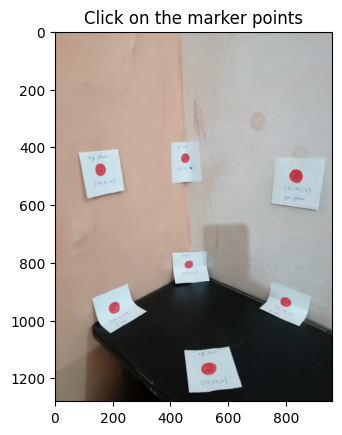

All clicked pixel coordinates: []


In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load the image
image_path = "/content/dl image.jpg"  # Change to your file path
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for Matplotlib

# Display the image and capture clicks
fig, ax = plt.subplots()
ax.imshow(image)
plt.title("Click on the marker points")

# List to store clicked points
clicked_points = []

def onclick(event):
    """Callback function to capture clicks"""
    if event.xdata is not None and event.ydata is not None:
        x, y = int(event.xdata), int(event.ydata)
        clicked_points.append((x, y))
        print(f"Clicked at: ({x}, {y})")
        ax.scatter(x, y, color='red')  # Mark clicked point
        fig.canvas.draw()

# Connect the click event
fig.canvas.mpl_connect('button_press_event', onclick)

plt.show()

# After clicking, print all points
print("All clicked pixel coordinates:", clicked_points)


In [8]:
import numpy as np

# Given 3D world coordinates (X, Y, Z)
world_points = np.array([
    [10, 0, 10, 1],
    [0, 0, 10, 1],
    [0, 10, 10, 1],
    [10, 0, 0, 1],
    [10, 10, 0, 1],
    [0, 10, 0, 1]
])

# Corresponding 2D pixel coordinates (u, v)
image_points = np.array([
    [77, 245],
    [227, 219],
    [417, 252],
    [104, 481],
    [271, 584],
    [398, 467]
])

# Build the matrix A for solving Ap = 0
A = []
for i in range(len(world_points)):
    X, Y, Z, W = world_points[i]
    u, v = image_points[i]

    A.append([-X, -Y, -Z, -W, 0, 0, 0, 0, u*X, u*Y, u*Z, u*W])
    A.append([0, 0, 0, 0, -X, -Y, -Z, -W, v*X, v*Y, v*Z, v*W])

A = np.array(A)

# Solve using Singular Value Decomposition (SVD)
U, S, Vt = np.linalg.svd(A)
P = Vt[-1].reshape(3, 4)  # The last row of V corresponds to the smallest singular value

print("Estimated Projection Matrix (P):\n", P)

# Extract camera center
P_3x3 = P[:, :3]
P_3x1 = P[:, 3]

camera_center = -np.linalg.inv(P_3x3) @ P_3x1
print("Estimated Camera Position (Cx, Cy, Cz):", camera_center)

Estimated Projection Matrix (P):
 [[ 0.03279713 -0.01952977  0.00655353 -0.50172659]
 [ 0.00497135  0.00345556  0.04498396 -0.86296331]
 [ 0.00004272  0.00003662  0.00002396 -0.0021279 ]]
Estimated Camera Position (Cx, Cy, Cz): [24.24040831 20.03946957 14.96551455]


It is close to actual distance
